# Wrong-Wavelength Summary — P2 / P4 / P6 / Const-WL / True-Wavelength, one comparison per (dataset, decoder)

Combines five conditions that all keep pixel data and normalization untouched and only change the
*wavelength label* fed to each wavelength-conditioned encoder's hypernetwork:

| Old name | Used here as | What it does |
|---|---|---|
| — | **True λ (S2)** | Baseline: the regular benchmark's default wavelength label (Sentinel-2 band names/centers for every dataset, including the 3 cross-sensor ones below) |
| — | **True Wavelength** | SpaceNet7-CD / FiveBillionPixels / m-Forestnet only: each sensor's *own* real center wavelengths (PlanetScope / GaoFen-2 / Landsat-derived), replacing the S2-default label those datasets normally get |
| P2 | **Within-Group Shuffle** | Random permutation of labels *within* a spectral group (VIS / Red-Edge-NIR / SWIR), 2 draws averaged |
| P4 | **Full Random Shuffle** | Unconstrained random permutation of the whole wavelength vector, 3 draws averaged |
| P6 | **Fully Random λ** | Each band gets an independent Uniform(400,2500nm) draw, no relation to any real sensor band, 2 draws averaged |
| Const-WL | **Constant λ (550nm)** | Every band relabeled to the same uninformative wavelength -- most severe condition |

P1 (**Neighbor Swap**) is loaded but excluded from every plot in this notebook -- its Δ23-43nm swaps
between spectrally adjacent bands were too mild to read clearly here.

Encoders: DOFA, DOFA+ (DOFAv2), Panopticon, Copernicus-FM, **CARL** (the `carl_imagewise` variant --
imagewise normalization is the standard used everywhere in this project from P1 onward; plain
dataset-wise CARL is intentionally excluded), **SMARTIES**. **ViT-Frozen-p16** (a frozen,
randomly-initialized ViT with no wavelength conditioning at all) is added as its own bar group at the
right of every plot -- it never had a wavelength ablation run (wavelength labels are meaningless to it),
but its fixed baseline score is a useful floor/ceiling for judging whether a corrupted wavelength-aware
encoder still retains any advantage over a model that never used wavelength information in the first
place.

**SMARTIES has no "Fully Random λ" (P6) bar.** Unlike the other 5 encoders, SMARTIES doesn't take a
continuous wavelength value at all -- each band name is mapped through a fixed lookup table onto one of
~18 discrete spectral-range projectors (see `smarties_encoder.py`). P2/P4/Const-WL still apply (they
swap/shuffle/collapse *named* bands, so each corrupted band still resolves to *some* valid discrete
projector), but P6's literal definition -- an unconstrained random float from Uniform(400,2500) -- has no
equivalent input SMARTIES can consume. This is a structural gap, not a missing run to backfill.

P2/P4 only exist for the UPerNet decoder (never run for MLP-Fusion). P6 and Const-WL exist for both
decoders (Const-WL also has a `cls_linear` variant for m-Forestnet). True-Wavelength only exists for the
3 cross-sensor datasets, both decoders (m-Forestnet's is decoder-agnostic `cls_linear`). One grouped bar
chart is produced per (dataset, decoder) combination that has baseline + at least one other condition
available.

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPERIMENTS_BASE = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments")

# ── Encoder display names (folder key -> display label) ─────────────────────
# carl_imagewise is CARL's standard/default variant here -- displayed simply as
# "CARL" (plain dataset-wise "carl" is intentionally left out entirely, same
# convention as the main results notebooks).
ENCODER_DISPLAY = {
    "dofa":               "DOFA",
    "dofav2":             "DOFA+",
    "copernicus_fm_base": "Copernicus-FM",
    "panopticon":         "Panopticon",
    "carl_imagewise":     "CARL",
    "smarties_vitb":      "SMARTIES",
}
# Bar order: DOFA, DOFA+, Copernicus-FM, Panopticon, CARL, SMARTIES, then the
# random-init ViT control last (own bar group, anchored at the far right).
# SMARTIES has no "Fully Random λ" (P6) bar -- see markdown above: it has no
# continuous wavelength input at all (fixed band-name -> discrete-projector
# lookup table), so a random float from Uniform(400,2500) has no equivalent in
# its architecture. Every other condition (P2/P4/Const-WL/True-WL/baseline)
# is present for it.
ENCODER_ORDER = ["DOFA", "DOFA+", "Copernicus-FM", "Panopticon", "CARL", "SMARTIES", "ViT-Frozen-p16"]

# Const-WL / True-Wavelength folders use short prefixes instead of the full encoder key
CONST_WL_SHORT = {
    "dofa": "dofa", "dofav2": "dofav2", "panopticon": "panopticon",
    "cfm": "copernicus_fm_base", "sm": "smarties_vitb",
    "carl_iw": "carl_imagewise",
}

# ── Dataset detection ─────────────────────────────────────────────────────────
DATASET_LABELS = {
    "mforestnet":         "m-Forestnet",
    "msa-crop-type":      "m-SA-Crop-Type",
    "mcashew-plantation": "m-Cashew-Plantation",
    "mados":              "MADOS",
    "hlsburnscars":       "HLS-BurnScars",
    "spacenet7cd":        "SpaceNet7-CD",
    "fivebillionpixels":  "FiveBillionPixels",
}
_DS_KEYS_SORTED = sorted(DATASET_LABELS, key=len, reverse=True)
DATASET_RE = re.compile(r"_(" + "|".join(re.escape(d) for d in _DS_KEYS_SORTED) + r")_")

METRIC_LABEL = {"m-Forestnet": "Accuracy (%)"}  # everything else defaults to mIoU

# "Neighbor Swap" (P1) is loaded (cell below) but intentionally excluded here --
# not part of CONDITION_ORDER, so plot_comparison() never shows it (its
# conditions list is always filtered against this).
CONDITION_ORDER = [
    "True λ (S2)", "True Wavelength", "Within-Group Shuffle",
    "Full Random Shuffle", "Fully Random λ", "Constant λ (550nm)",
]

print("Config loaded.")

# ── Plot style (matching the his-bench_dev wrong-wavelength notebook) ───────
GRID_COLOR = "#e3e2dd"
TEXT_MUTED = "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#c9c8c2",
    "font.size": 10,
})

# Fixed categorical color per condition, blue (baseline) -> red (most severe),
# reused identically across every chart in this notebook. "True Wavelength" gets
# its own purple, distinct from the severity ramp -- it isn't a corruption, it's
# an alternate (arguably more correct) ground truth for the 3 cross-sensor datasets.
CONDITION_COLORS = {
    "True λ (S2)":          "#2a78d6",
    "True Wavelength":            "#8e44ad",
    "Within-Group Shuffle":       "#eda100",
    "Full Random Shuffle":        "#eb6834",
    "Fully Random λ":       "#c0392b",
    "Constant λ (550nm)":   "#8e1b1b",
}


Config loaded.


In [2]:
def parse_log_metrics(log_path: Path) -> dict:
    """Parse segmentation train.log-0 -- returns test_mIoU etc. (last [test] block)."""
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- IoU", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- IoU" + sections[-1]
    m = re.search(r"\[test\] ------- IoU.*?\[test\] Mean\s+([\d.]+)", test_block, re.DOTALL)
    return {"test_mIoU": float(m.group(1))} if m else {}


def parse_cls_log_metrics(log_path: Path) -> dict:
    """Parse classification train.log-0 -- returns test_Accuracy (last [test] block)."""
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- Accuracy", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- Accuracy" + sections[-1]
    m = re.search(r"\[test\] ------- Accuracy.*?\[test\] Mean\s+([\d.]+)", test_block, re.DOTALL)
    return {"test_Accuracy": float(m.group(1))} if m else {}


def load_folder_runs(folder: Path, encoder_disp: str, decoder_label: str, condition_label: str, draw=None) -> list[dict]:
    """Scan one experiment subfolder (already known encoder/condition/decoder) for run dirs, one row per dataset found.

    If a folder holds more than one run for the same dataset, the last one (by sorted
    run-dir name) wins rather than both being kept. Run-dir names are timestamp-prefixed,
    so this means a rerun supersedes a stale run instead of both later getting blended by
    the groupby-mean downstream -- same "last wins" convention as aggfunc="last" elsewhere
    in this project. This matters concretely for the True-Wavelength SpaceNet7-CD runs,
    which were rerun after the dice-loss collapse fix and left the old run directories in
    place alongside the fixed reruns.
    """
    if not folder.exists():
        return []
    by_dataset: dict[str, dict] = {}
    for run_dir in sorted(folder.iterdir()):
        if not run_dir.is_dir():
            continue
        m = DATASET_RE.search(run_dir.name)
        if not m:
            continue
        ds_raw = m.group(1)
        ds_label = DATASET_LABELS[ds_raw]
        log = run_dir / "train.log-0"
        if ds_raw == "mforestnet":
            v = parse_cls_log_metrics(log).get("test_Accuracy")
            val = v * 100 if v is not None else None
        else:
            val = parse_log_metrics(log).get("test_mIoU")
        if val is None:
            continue
        # m-Forestnet is always a decoder-agnostic linear probe (cls_linear) --
        # override whatever decoder label this experiment folder normally uses.
        dec_label = "Linear-Classification" if ds_raw == "mforestnet" else decoder_label
        by_dataset[ds_label] = dict(encoder=encoder_disp, dataset=ds_label, decoder=dec_label,
                                     condition=condition_label, draw=draw, metric=val, run_dir=run_dir.name)
    return list(by_dataset.values())


print("Parse/load functions defined.")

Parse/load functions defined.


In [3]:
P1_BASE  = EXPERIMENTS_BASE / "p1_wlswap_ablation"
P2_BASE  = EXPERIMENTS_BASE / "p2_wlswap_ablation"
P4_BASE  = EXPERIMENTS_BASE / "p4_wlswap_ablation"
P6_MLP_BASE = EXPERIMENTS_BASE / "p6_random_wl_ablation"
P6_UP_BASE  = EXPERIMENTS_BASE / "p6_random_wl_ablation_upernet"
CONST_WL_BASE = EXPERIMENTS_BASE / "wavelength_ablation_const_wl"

PANGAEA_UP_BASE  = EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet"
PANGAEA_MLP_BASE = EXPERIMENTS_BASE / "pangaea_full_seg" / "mlp_fusion"
GEOBENCH_UP_BASE  = EXPERIMENTS_BASE / "geobench" / "seg" / "UPerNet"
GEOBENCH_MLP_BASE = EXPERIMENTS_BASE / "geobench" / "seg" / "MLPFusion"
GEOBENCH_CLS_BASE = EXPERIMENTS_BASE / "geobench" / "cls"

all_rows = []

# ── P1 -- Neighbor Swap (UPerNet only, single run, no draws) ────────────────
for enc_key, enc_disp in ENCODER_DISPLAY.items():
    all_rows += load_folder_runs(P1_BASE / enc_key, enc_disp, "UPerNet", "Neighbor Swap")

# ── P2 -- Within-Group Shuffle (UPerNet only, 2 draws) ───────────────────────
for enc_key, enc_disp in ENCODER_DISPLAY.items():
    for draw in ["A", "B"]:
        all_rows += load_folder_runs(P2_BASE / f"{enc_key}_draw{draw}", enc_disp, "UPerNet",
                                      "Within-Group Shuffle", draw=draw)

# ── P4 -- Full Random Shuffle (UPerNet only, 3 draws) ────────────────────────
for enc_key, enc_disp in ENCODER_DISPLAY.items():
    for draw in ["1", "2", "3"]:
        all_rows += load_folder_runs(P4_BASE / f"{enc_key}_draw{draw}", enc_disp, "UPerNet",
                                      "Full Random Shuffle", draw=draw)

# ── P6 -- Fully Random \u03bb (MLP-Fusion: 3 draws, UPerNet: 2 draws) ───────
for enc_key, enc_disp in ENCODER_DISPLAY.items():
    for draw in ["1", "2", "3"]:
        all_rows += load_folder_runs(P6_MLP_BASE / f"{enc_key}_draw{draw}", enc_disp, "MLP-Fusion",
                                      "Fully Random \u03bb", draw=draw)
    for draw in ["1", "2"]:
        all_rows += load_folder_runs(P6_UP_BASE / f"{enc_key}_draw{draw}", enc_disp, "UPerNet",
                                      "Fully Random \u03bb", draw=draw)

# ── Const-WL -- Constant \u03bb (550nm), 3 decoder variants ─────────────────
CONST_WL_DECODER = {"up": "UPerNet", "mlp": "MLP-Fusion", "cls": "Linear-Classification"}
for short, enc_key in CONST_WL_SHORT.items():
    enc_disp = ENCODER_DISPLAY[enc_key]
    for suffix, dec_label in CONST_WL_DECODER.items():
        all_rows += load_folder_runs(CONST_WL_BASE / f"{short}_const_wl_{suffix}", enc_disp, dec_label,
                                      "Constant \u03bb (550nm)")

print(f"{len(all_rows)} rows loaded across P1/P2/P4/P6/Const-WL.")

318 rows loaded across P1/P2/P4/P6/Const-WL.


In [4]:
# ── True Wavelength -- SpaceNet7-CD / FiveBillionPixels / m-Forestnet only ──
# These 3 cross-sensor datasets (PlanetScope / GaoFen-2 / Landsat-derived) get
# their bands labeled with the nearest Sentinel-2 band name as a convenience
# default everywhere else in this notebook -- that default is what "True λ (S2)"
# measures for them too. This dedicated ablation instead feeds each sensor's own
# real center wavelengths into the hypernetwork (pixels and labels unchanged).
TRUE_WL_UP_BASE  = EXPERIMENTS_BASE / "wavelength_ablation"
TRUE_WL_MLP_BASE = EXPERIMENTS_BASE / "wavelength_ablation_mlpfusion"
SHORT_BY_ENC_KEY = {v: k for k, v in CONST_WL_SHORT.items()}

for enc_key, enc_disp in ENCODER_DISPLAY.items():
    short = SHORT_BY_ENC_KEY[enc_key]
    all_rows += load_folder_runs(TRUE_WL_UP_BASE / f"{short}_wl_ablation", enc_disp, "UPerNet", "True Wavelength")
    all_rows += load_folder_runs(TRUE_WL_MLP_BASE / f"{short}_wl_ablation", enc_disp, "MLP-Fusion", "True Wavelength")

print(f"{len(all_rows)} rows loaded across P1/P2/P4/P6/Const-WL/True-Wavelength.")

348 rows loaded across P1/P2/P4/P6/Const-WL/True-Wavelength.


In [5]:
# ── Baselines (True \u03bb / S2) -- regular benchmark + GeoBench sources ────
BASELINE_UP_FOLDER  = {k: f"{k}_seg" for k in ENCODER_DISPLAY}
BASELINE_MLP_FOLDER = {k: f"{k}_mlp_fusion" for k in ENCODER_DISPLAY}

for enc_key, enc_disp in ENCODER_DISPLAY.items():
    all_rows += load_folder_runs(PANGAEA_UP_BASE / BASELINE_UP_FOLDER[enc_key], enc_disp, "UPerNet", "True \u03bb (S2)")
    all_rows += load_folder_runs(PANGAEA_MLP_BASE / BASELINE_MLP_FOLDER[enc_key], enc_disp, "MLP-Fusion", "True \u03bb (S2)")
    all_rows += load_folder_runs(GEOBENCH_UP_BASE / enc_key, enc_disp, "UPerNet", "True \u03bb (S2)")
    all_rows += load_folder_runs(GEOBENCH_MLP_BASE / enc_key, enc_disp, "MLP-Fusion", "True \u03bb (S2)")
    all_rows += load_folder_runs(GEOBENCH_CLS_BASE / enc_key, enc_disp, "Linear-Classification", "True \u03bb (S2)")

# ── ViT-Frozen-p16 reference (no wavelength conditioning -- baseline only) ──
all_rows += load_folder_runs(PANGAEA_UP_BASE / "vit_scratch_frozen_encoder_seg", "ViT-Frozen-p16", "UPerNet", "True \u03bb (S2)")
all_rows += load_folder_runs(PANGAEA_MLP_BASE / "vit_scratch_frozen_encoder_mlp_fusion", "ViT-Frozen-p16", "MLP-Fusion", "True \u03bb (S2)")
all_rows += load_folder_runs(GEOBENCH_UP_BASE / "vit_frozen_p16", "ViT-Frozen-p16", "UPerNet", "True \u03bb (S2)")
all_rows += load_folder_runs(GEOBENCH_MLP_BASE / "vit_frozen_p16", "ViT-Frozen-p16", "MLP-Fusion", "True \u03bb (S2)")
all_rows += load_folder_runs(GEOBENCH_CLS_BASE / "vit_frozen_p16", "ViT-Frozen-p16", "Linear-Classification", "True \u03bb (S2)")

df_all = pd.DataFrame(all_rows)
print(f"{len(df_all)} rows total (incl. baselines + ViT-Frozen-p16 reference).")

# Average over draws (P2/P4/P6) so each (encoder, dataset, decoder, condition) has one value
df_agg = df_all.groupby(["encoder", "dataset", "decoder", "condition"], as_index=False)["metric"].mean()
print(f"{len(df_agg)} rows after averaging draws.")

439 rows total (incl. baselines + ViT-Frozen-p16 reference).
302 rows after averaging draws.


## Coverage check -- which (dataset, decoder) combos have data for which conditions

In [6]:
coverage = (
    df_agg[df_agg["encoder"] != "ViT-Frozen-p16"]
    .pivot_table(index=["dataset", "decoder"], columns="condition", values="metric", aggfunc="count")
    .reindex(columns=[c for c in CONDITION_ORDER])
)
coverage

condition                                  True λ (S2)  True Wavelength  \
dataset             decoder                                               
FiveBillionPixels   MLP-Fusion                     6.0              6.0   
                    UPerNet                        6.0              6.0   
HLS-BurnScars       MLP-Fusion                     6.0              NaN   
                    UPerNet                        6.0              NaN   
MADOS               MLP-Fusion                     6.0              NaN   
                    UPerNet                        6.0              NaN   
SpaceNet7-CD        MLP-Fusion                     6.0              6.0   
                    UPerNet                        6.0              6.0   
m-Cashew-Plantation MLP-Fusion                     6.0              NaN   
                    UPerNet                        6.0              NaN   
m-Forestnet         Linear-Classification          6.0              6.0   
m-SA-Crop-Type      MLP-Fusion                     6.0              NaN   
                    UPerNet                        6.0              NaN   

condition                                  Within-Group Shuffle  \
dataset             decoder                                       
FiveBillionPixels   MLP-Fusion                              NaN   
                    UPerNet                                 NaN   
HLS-BurnScars       MLP-Fusion                              NaN   
                    UPerNet                                 NaN   
MADOS               MLP-Fusion                              NaN   
                    UPerNet                                 6.0   
SpaceNet7-CD        MLP-Fusion                              NaN   
                    UPerNet                                 NaN   
m-Cashew-Plantation MLP-Fusion                              NaN   
                    UPerNet                                 6.0   
m-Forestnet         Linear-Classification                   6.0   
m-SA-Crop-Type      MLP-Fusion                              NaN   
                    UPerNet                                 6.0   

condition                                  Full Random Shuffle  \
dataset             decoder                                      
FiveBillionPixels   MLP-Fusion                             NaN   
                    UPerNet                                NaN   
HLS-BurnScars       MLP-Fusion                             NaN   
                    UPerNet                                NaN   
MADOS               MLP-Fusion                             NaN   
                    UPerNet                                6.0   
SpaceNet7-CD        MLP-Fusion                             NaN   
                    UPerNet                                NaN   
m-Cashew-Plantation MLP-Fusion                             NaN   
                    UPerNet                                6.0   
m-Forestnet         Linear-Classification                  6.0   
m-SA-Crop-Type      MLP-Fusion                             NaN   
                    UPerNet                                6.0   

condition                                  Fully Random λ  Constant λ (550nm)  
dataset             decoder                                                    
FiveBillionPixels   MLP-Fusion                        5.0                 NaN  
                    UPerNet                           5.0                 NaN  
HLS-BurnScars       MLP-Fusion                        NaN                 6.0  
                    UPerNet                           NaN                 6.0  
MADOS               MLP-Fusion                        5.0                 6.0  
                    UPerNet                           5.0                 6.0  
SpaceNet7-CD        MLP-Fusion                        5.0                 NaN  
                    UPerNet                           5.0                 NaN  
m-Cashew-Plantation MLP-Fusion                        5.0                 6.0

## How the "Fully Random λ" (P6) wavelengths were drawn

Each band gets an independent draw from **Uniform(400, 2500) nm** -- the range spanning Sentinel-2's
VIS/NIR/SWIR bands and beyond, with *no* relationship to that band's real center wavelength (unlike
P1/P2/P4/Const-WL, which all still start from the real S2 vector and swap/shuffle/flatten it). Two seeded
draws are used (seed 501 / seed 502, each with a per-dataset offset so e.g. MADOS and m-Forestnet don't
draw correlated values from the "same" seed), and every plot in this notebook averages over both. Values
are rejection-sampled: redraw until every pair of wavelengths within one band vector is at least 5nm
apart -- a degeneracy guard against two bands accidentally landing on (almost) the same label, not a
physical constraint.

The panel below shows exactly where each band's label landed for both draws, per dataset-band-group --
solid line from the band's real center wavelength (left) to its random draw (right).

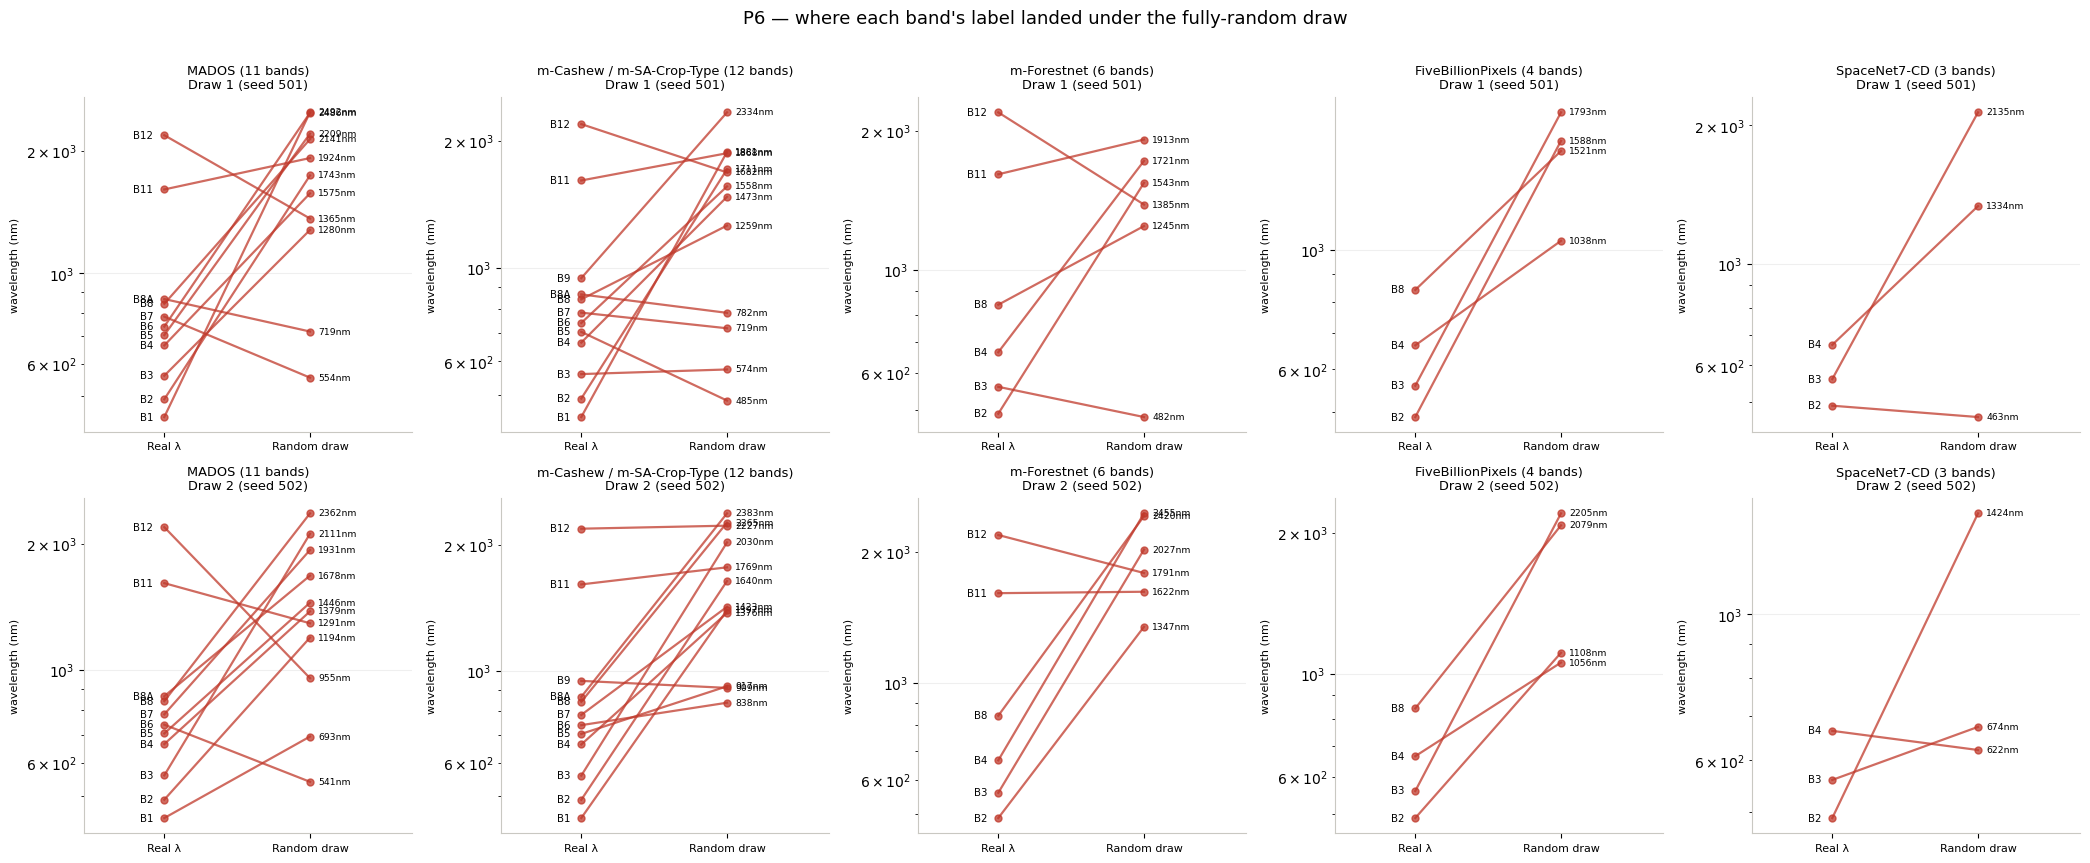

In [7]:
import json as _json

with open("../scripts/slurm_scripts/wavelength_ablation/p6_random_wl_draws.json") as f:
    p6_manifest = _json.load(f)

REF_WL_NM = {
    "B1": 443, "B2": 490, "B3": 560, "B4": 665, "B5": 705, "B6": 740, "B7": 783,
    "B8": 842, "B8A": 865, "B9": 945, "B11": 1610, "B12": 2190,
}
ORDER_MADOS = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
ORDER_12B   = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"]
ORDER_MFN   = ["B2", "B3", "B4", "B8", "B11", "B12"]
ORDER_SN7CD = ["B4", "B3", "B2"]
ORDER_FBP   = ["B8", "B4", "B3", "B2"]


def plot_p6_random_panel(ax, dsgroup, draw, order, title):
    vals = p6_manifest["sampled_values_nm"][draw][dsgroup]
    for b in order:
        y0, y1 = REF_WL_NM[b], vals[b]
        ax.plot([0, 1], [y0, y1], color=CONDITION_COLORS["Fully Random λ"], alpha=0.75,
                linewidth=1.6, marker="o", markersize=5, zorder=3)
        ax.annotate(b, (0, y0), textcoords="offset points", xytext=(-8, 0), ha="right", va="center", fontsize=7.3)
        ax.annotate(f"{y1:.0f}nm", (1, y1), textcoords="offset points", xytext=(6, 0),
                     ha="left", va="center", fontsize=6.6)
    ax.set_yscale("log")
    ax.set_xlim(-0.55, 1.7)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Real λ", "Random draw"], fontsize=8)
    ax.set_ylabel("wavelength (nm)", fontsize=8)
    ax.set_title(title, fontsize=9.3)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)


groups = [
    ("mados",  ORDER_MADOS, "MADOS (11 bands)"),
    ("s2_12b", ORDER_12B,   "m-Cashew / m-SA-Crop-Type (12 bands)"),
    ("mfn",    ORDER_MFN,   "m-Forestnet (6 bands)"),
    ("fbp",    ORDER_FBP,   "FiveBillionPixels (4 bands)"),
    ("sn7cd",  ORDER_SN7CD, "SpaceNet7-CD (3 bands)"),
]
fig, axes = plt.subplots(2, len(groups), figsize=(4.2 * len(groups), 8.5))
for col, (dsgroup, order, label) in enumerate(groups):
    plot_p6_random_panel(axes[0, col], dsgroup, "1", order, f"{label}\nDraw 1 (seed 501)")
    plot_p6_random_panel(axes[1, col], dsgroup, "2", order, f"{label}\nDraw 2 (seed 502)")
fig.suptitle("P6 — where each band's label landed under the fully-random draw", fontsize=13, y=1.01)
fig.tight_layout()
plt.show()

## Comparison plots -- one grouped bar chart per (dataset, decoder)

The last five combos below (m-Forestnet, FiveBillionPixels ×2 decoders, SpaceNet7-CD ×2 decoders) carry
an extra **True Wavelength** bar: these are the only 3 datasets where the S2-default label used
everywhere else in this notebook isn't actually correct, so they get a genuine three-way comparison --
**True λ (S2)** vs. **Fully Random λ** vs. **True Wavelength** -- while the native-S2 datasets only ever
have the baseline vs. corruption conditions.

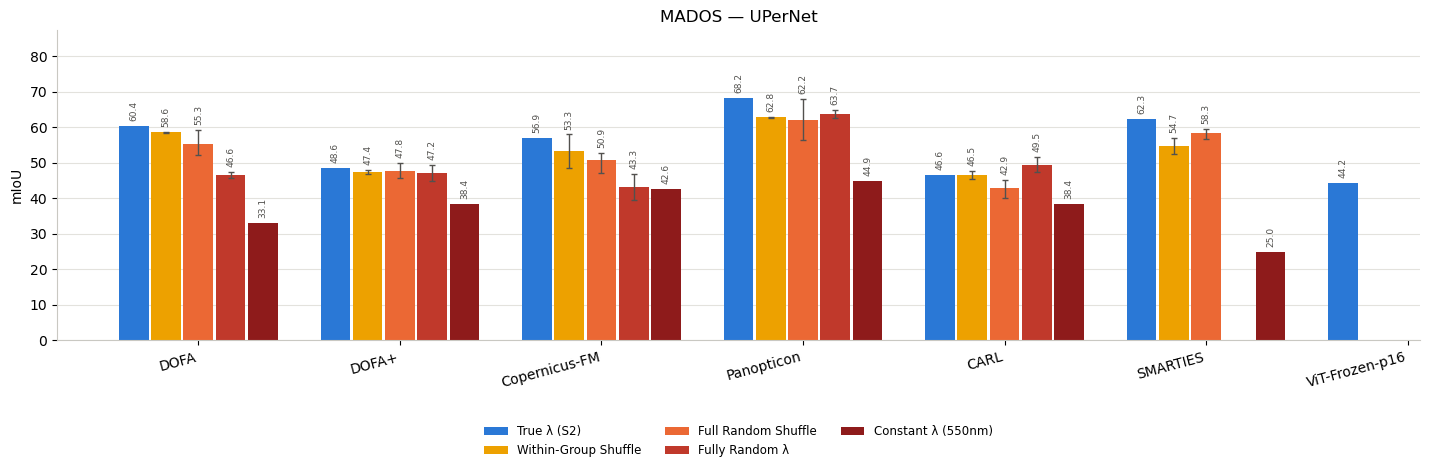

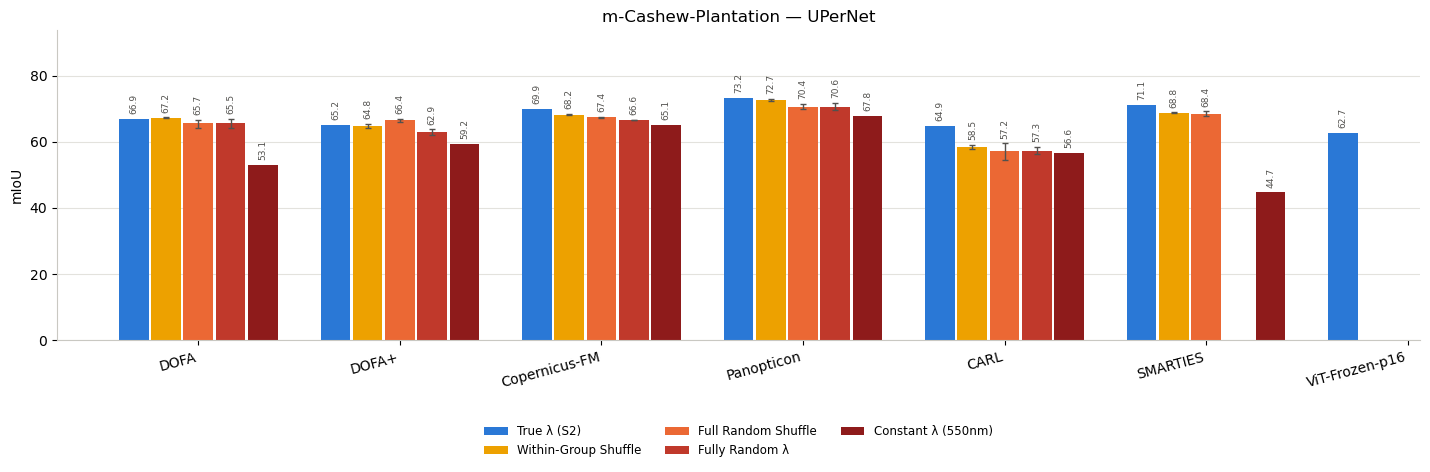

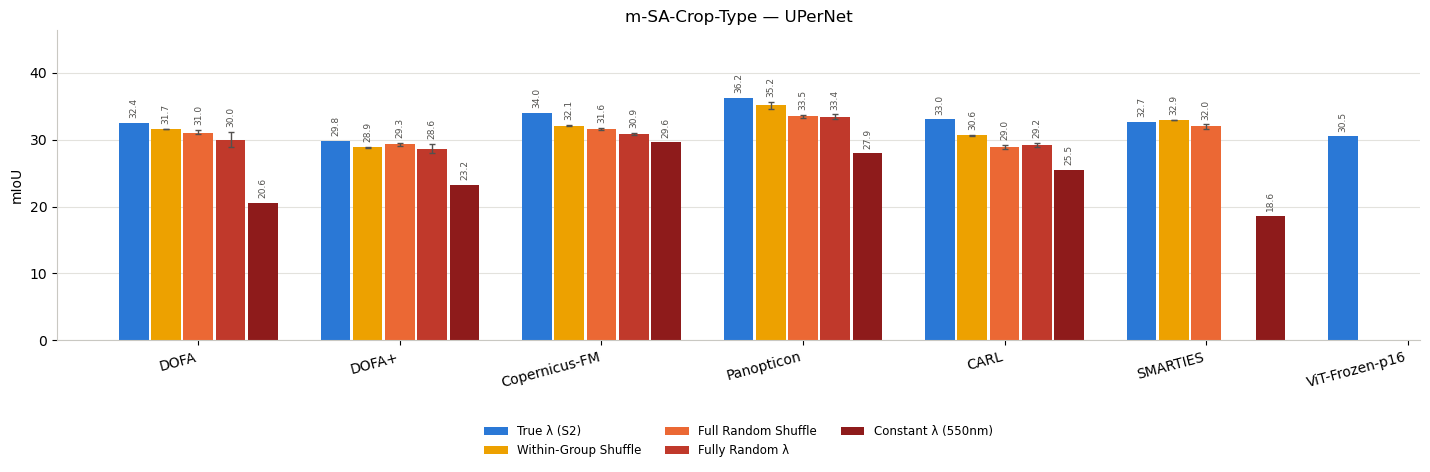

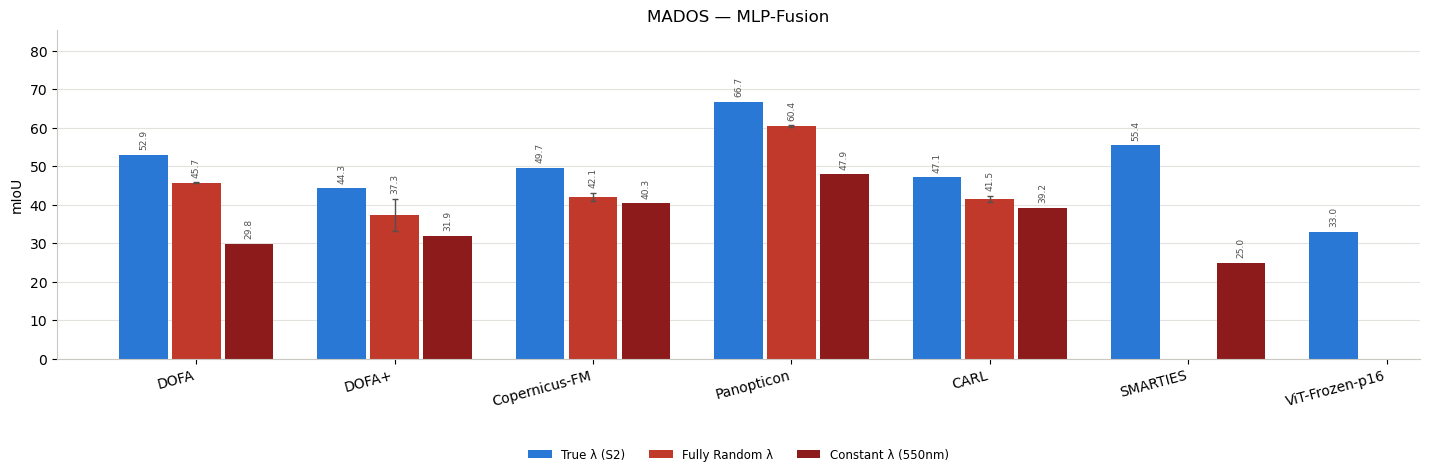

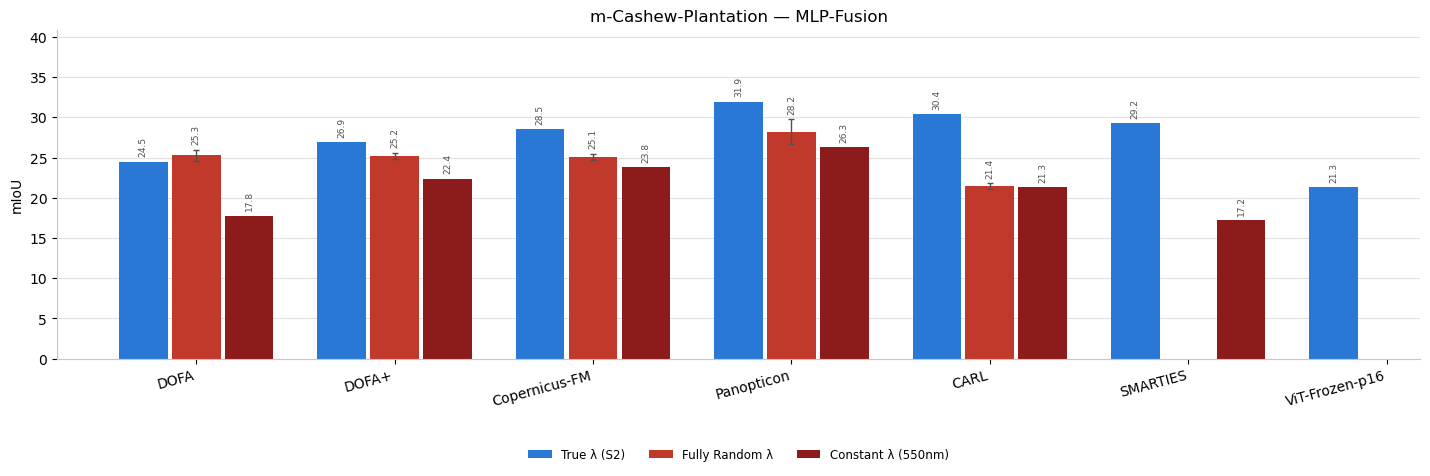

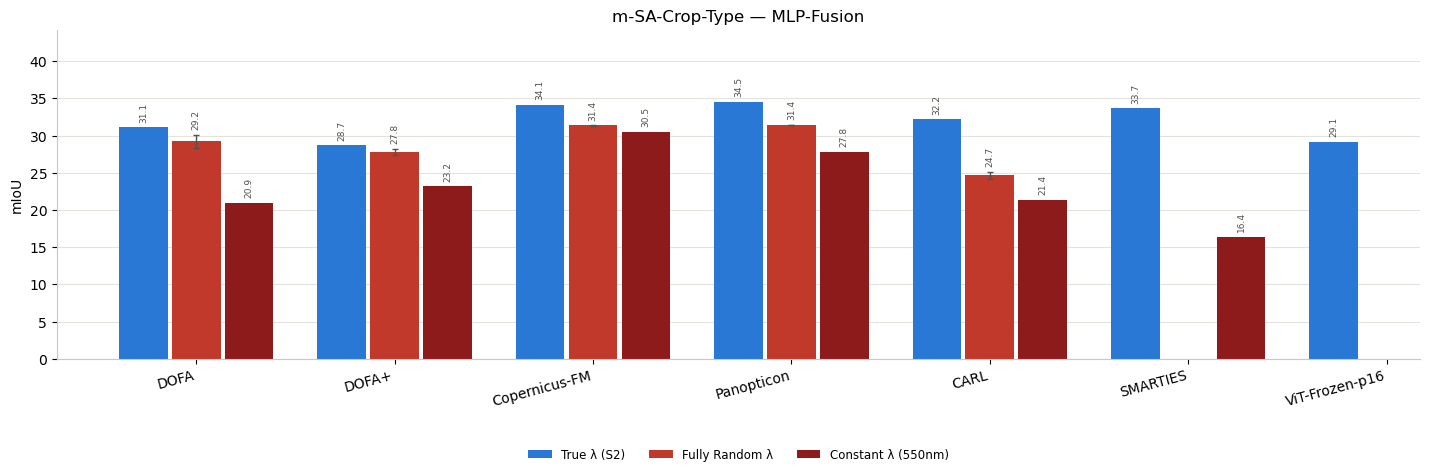

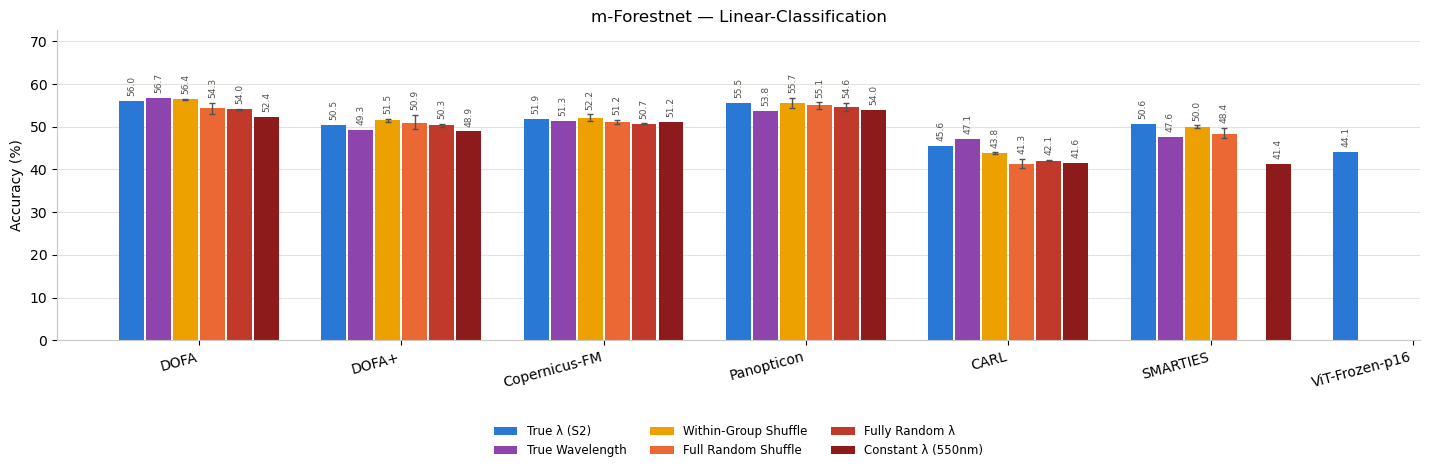

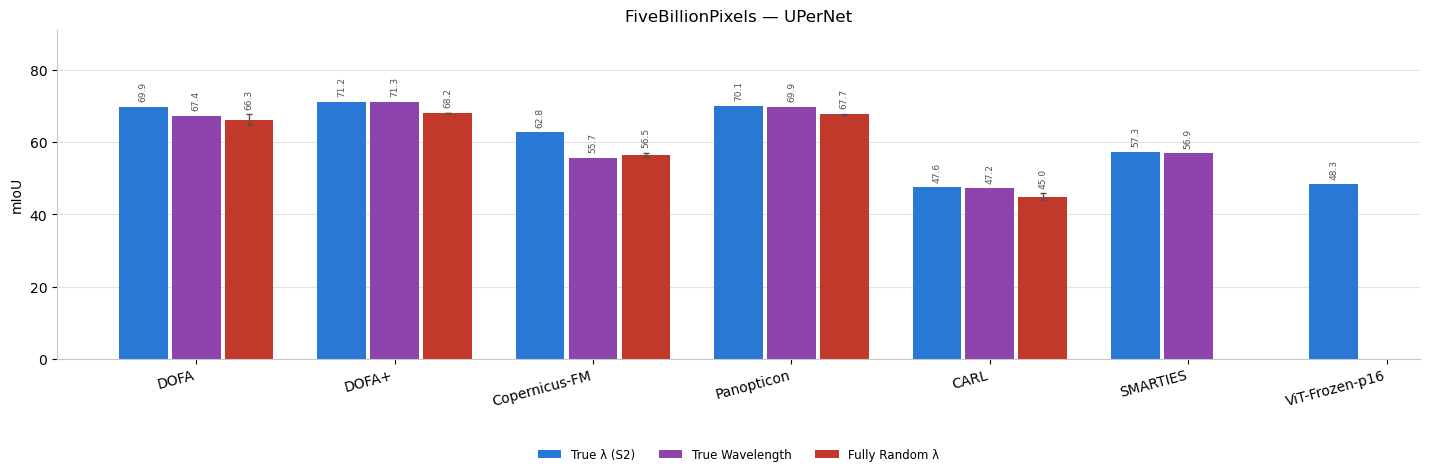

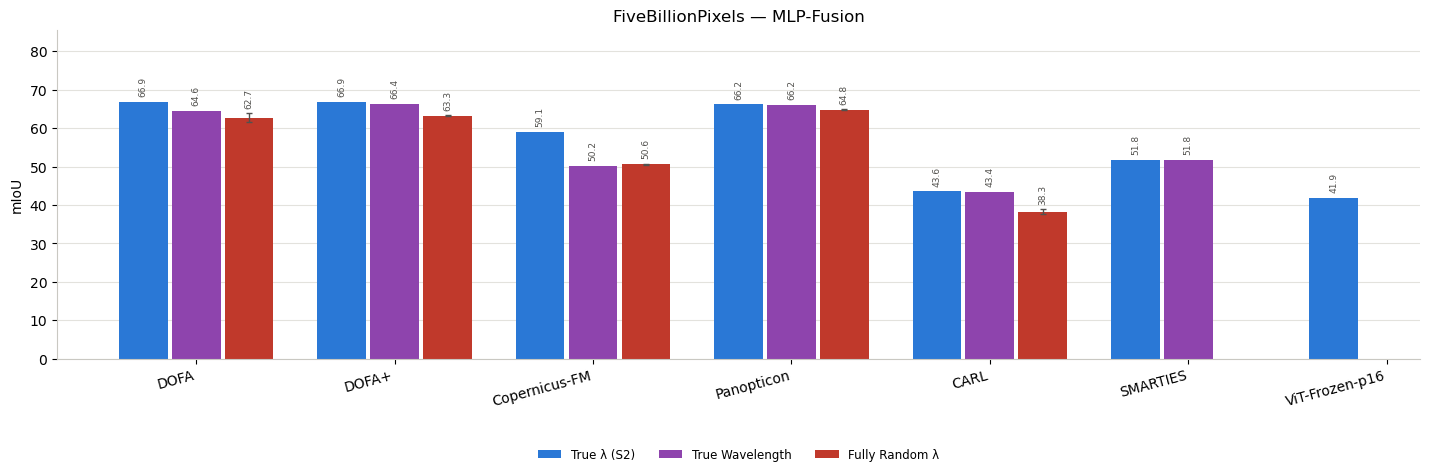

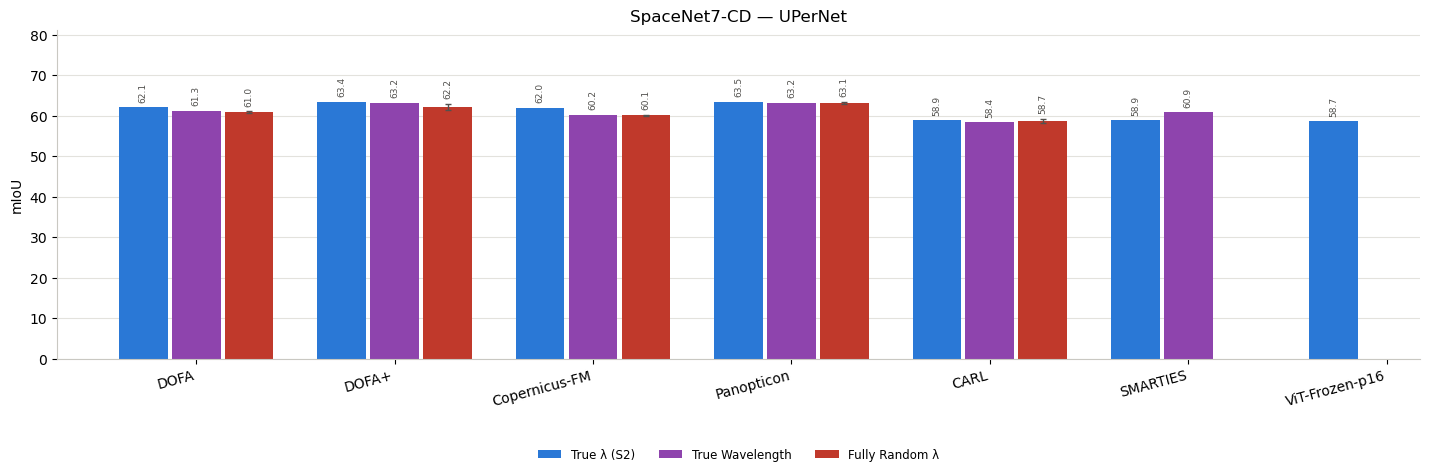

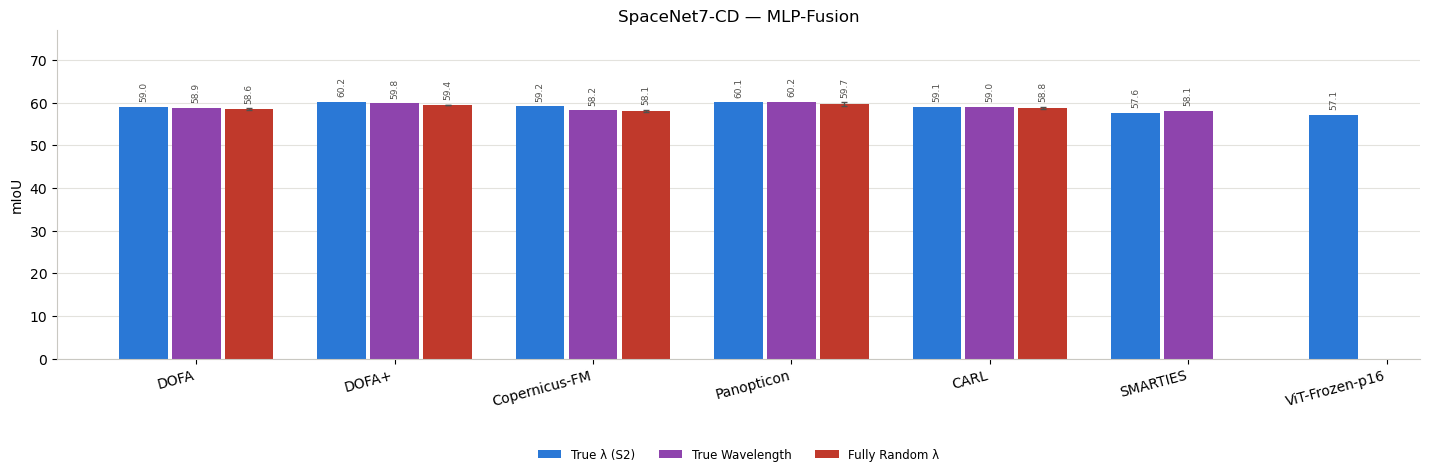

In [8]:
def get_condition_value(dataset: str, decoder: str, encoder: str, condition: str):
    """Returns (mean, lower_err, upper_err) for one (dataset, decoder, encoder, condition),
    computed straight from the raw per-draw rows in df_all (mirrors the sibling
    his-bench_dev notebook's get_condition_value)."""
    sub = df_all[(df_all["dataset"] == dataset) & (df_all["decoder"] == decoder)
                 & (df_all["encoder"] == encoder) & (df_all["condition"] == condition)]
    v = sub["metric"].dropna()
    if len(v) == 0:
        return (np.nan, 0.0, 0.0)
    m = v.mean()
    return (m, m - v.min(), v.max() - m)


def plot_comparison(dataset: str, decoder: str, encoders: list[str] | None = None,
                     conditions: list[str] | None = None):
    """conditions=None (default) auto-detects every condition with data for this
    (dataset, decoder). Pass an explicit subset (e.g. just the 3-way True-λ(S2) /
    Fully-Random-λ / True-Wavelength comparison) to restrict the chart even when
    more conditions exist, e.g. m-Forestnet also has the full P2/P4/Const-WL ladder."""
    encoders = encoders or ENCODER_ORDER
    if conditions is None:
        conditions = [
            c for c in CONDITION_ORDER
            if not df_all[(df_all["dataset"] == dataset) & (df_all["decoder"] == decoder)
                          & (df_all["condition"] == c)].empty
        ]
    else:
        conditions = [
            c for c in conditions
            if not df_all[(df_all["dataset"] == dataset) & (df_all["decoder"] == decoder)
                          & (df_all["condition"] == c)].empty
        ]
    if len(conditions) < 2:   # need baseline + at least one perturbation to be worth plotting
        return False

    n_cond, n_enc = len(conditions), len(encoders)
    bar_width = 0.8 / n_cond
    x = np.arange(n_enc)

    per_cond = {}
    for condition in conditions:
        vals, los, his = [], [], []
        for enc in encoders:
            m, lo, hi = get_condition_value(dataset, decoder, enc, condition)
            vals.append(m); los.append(lo); his.append(hi)
        per_cond[condition] = (vals, los, his)

    finite_maxes = [np.nanmax(v) for (v, _, _) in per_cond.values() if not np.all(np.isnan(v))]
    y_max = max(0.05, max(finite_maxes) if finite_maxes else 0.05)
    label_pad = y_max * 0.02

    fig, ax = plt.subplots(figsize=(1.7 * n_enc + 2.5, 5.0))
    for i, condition in enumerate(conditions):
        offset = (i - (n_cond - 1) / 2) * bar_width
        vals, los, his = per_cond[condition]
        yerr = np.array([los, his])
        has_err = np.any(yerr > 1e-9)
        ax.bar(
            x + offset, vals, width=bar_width * 0.92, color=CONDITION_COLORS[condition],
            label=condition, yerr=yerr if has_err else None,
            capsize=2, error_kw={"linewidth": 1, "ecolor": TEXT_MUTED},
        )
        for xi, v, hi in zip(x + offset, vals, his):
            if np.isnan(v):
                continue
            top = v + (hi if has_err else 0.0)
            ax.text(xi, top + label_pad, f"{v:.1f}", ha="center", va="bottom",
                    fontsize=6.5, rotation=90, color=TEXT_MUTED)

    ax.set_xticks(x)
    ax.set_xticklabels(encoders, rotation=15, ha="right")
    ax.set_ylabel(METRIC_LABEL.get(dataset, "mIoU"))
    ax.set_title(f"{dataset} — {decoder}")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, linewidth=0.8, color=GRID_COLOR)
    ax.set_axisbelow(True)
    ax.set_ylim(0, y_max * 1.28)
    ax.legend(frameon=False, ncols=min(n_cond, 3), loc="upper center",
              bbox_to_anchor=(0.5, -0.24), fontsize=8.5)
    fig.tight_layout()
    plt.show()
    return True


COMBOS = [
    ("MADOS", "UPerNet"), ("m-Cashew-Plantation", "UPerNet"), ("m-SA-Crop-Type", "UPerNet"),
    ("MADOS", "MLP-Fusion"), ("m-Cashew-Plantation", "MLP-Fusion"), ("m-SA-Crop-Type", "MLP-Fusion"),
    ("m-Forestnet", "Linear-Classification"),
    ("FiveBillionPixels", "UPerNet"), ("FiveBillionPixels", "MLP-Fusion"),
    ("SpaceNet7-CD", "UPerNet"), ("SpaceNet7-CD", "MLP-Fusion"),
]
for ds, dec in COMBOS:
    ok = plot_comparison(ds, dec)
    if not ok:
        print(f"skipped {ds} / {dec} -- insufficient data")


## Landsat-8 (m-Forestnet) — True λ (S2) vs. Fully Random λ vs. True Wavelength

m-Forestnet is the 4th cross-sensor dataset (Landsat-8 OLI, `L8_*` bands) and, unlike FiveBillionPixels
and SpaceNet7-CD, it also has the full P1/P2/P4/Const-WL ladder (already shown above in its own combined
chart). This isolates the same clean 3-way comparison used for FiveBillionPixels/SpaceNet7-CD --
S2-default label vs. fully random label vs. Landsat-8's own real center wavelengths -- so all three
cross-sensor datasets are directly comparable on the same 3-bar layout.

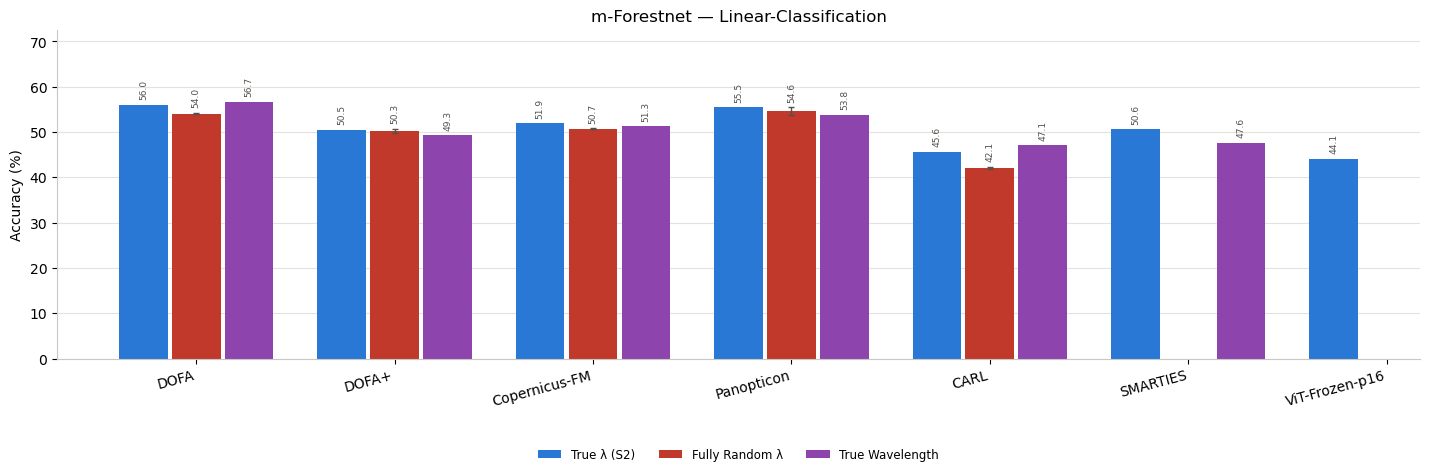

True

In [9]:
plot_comparison(
    "m-Forestnet", "Linear-Classification",
    conditions=["True λ (S2)", "Fully Random λ", "True Wavelength"],
)